# Quick Commerce Platform Analysis 🛵📦

**Goal:** Analyse quick commerce (q-commerce) order data across platforms like Swiggy Instamart, Blinkit, Zepto, and BigBasket Now to compare platform revenues, delivery efficiency, customer ratings, discount impact, and city-wise expansion potential — and build a mini KPI dashboard summarising key business metrics.

**Dataset:** Quick Commerce Dataset — real-world style order records with columns including Order_ID, Company, City, Customer_Age, Customer_Rating, Delivery_Time_Min, Delivery_Partner_Rating, Order_Value, Items_Count, Product_Category, Discount_Applied, and Distance_Km.

**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn · Plotly · Scikit-learn (MinMaxScaler)

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px

In [106]:
# Load Dataset
data = pd.read_csv('quick_commerce_data_raw.csv')
data.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.33750,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2
1,1000002,Flipkart Minutes,Amritsar,56,1007.30000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,NaN,Personal Care,Cash on Delivery,3.3,0,3.8
3,1000004,Swiggy Instamart,Delhi,23,1179.05925,5.864,6.44,2.0,Dairy,Credit Card,5.0,1,5.0
4,1000005,Dunzo,Mumbai,44,586.02550,12.470,2.45,13.0,Household,Wallet,3.7,0,4.8


In [107]:
# Dataset structure
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Order_ID                 1000000 non-null  int64  
 1   Company                  1000000 non-null  object 
 2   City                     948000 non-null   object 
 3   Customer_Age             1000000 non-null  int64  
 4   Order_Value              1000000 non-null  float64
 5   Delivery_Time_Min        1000000 non-null  float64
 6   Distance_Km              1000000 non-null  float64
 7   Items_Count              965000 non-null   float64
 8   Product_Category         1000000 non-null  object 
 9   Payment_Method           1000000 non-null  object 
 10  Customer_Rating          953000 non-null   float64
 11  Discount_Applied         1000000 non-null  int64  
 12  Delivery_Partner_Rating  895863 non-null   float64
dtypes: float64(6), int64(3), object(4)
memory u

In [108]:
# Dataset Statistics
data.describe()

,Order_ID,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,965000.000000,953000.000000,1000000.000000,895863.000000
mean,1.500000e+06,38.470387,571.643584,16.452412,7.750231,9.998317,3.042072,0.400883,3.749257
std,2.886753e+05,12.118520,382.784520,6.257172,4.186665,5.478725,1.186872,0.490078,0.722121
min,1.000001e+06,18.000000,50.000000,5.000000,0.500000,1.000000,1.000000,0.000000,2.500000
25%,1.250001e+06,28.000000,287.840150,12.368000,4.130000,5.000000,2.000000,0.000000,3.100000
50%,1.500000e+06,38.000000,531.324600,16.342000,7.740000,10.000000,3.000000,0.000000,3.700000
75%,1.750000e+06,49.000000,796.182500,20.196000,11.380000,15.000000,4.000000,1.000000,4.400000
max,2.000000e+06,59.000000,13877.325000,40.000000,15.000000,19.000000,5.000000,1.000000,5.000000


In [109]:
# Check Missing Values
data.isna().sum()

,0
Order_ID,0
Company,0
City,52000
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,35000
Product_Category,0
Payment_Method,0


In [110]:
# To show the records which contains ANY or ALL null values

data[data.isna().any(axis=1)]

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,NaN,Personal Care,Cash on Delivery,3.3,0,3.8
6,1000007,Blinkit,Bengluru,37,516.86480,18.476,12.46,19.0,Snacks,Debit Card,2.8,0,NaN
17,1000018,Zepto,Delhi,23,1041.42975,5.000,14.74,18.0,Snacks,Wallet,NaN,1,NaN
21,1000022,Blinkit,NaN,41,716.89860,17.804,11.34,7.0,Beverages,Credit Card,2.7,1,3.6
22,1000023,Jio Mart,Delhi,48,50.00000,8.498,0.83,3.0,Snacks,Cash on Delivery,3.1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999966,1999967,Dunzo,NaN,39,783.89250,18.820,14.70,NaN,Household,Wallet,3.1,1,4.9
999975,1999976,Amazon Now,Bengluru,34,515.89380,21.294,10.49,10.0,Fruits & Vegetables,Wallet,NaN,1,3.0
999981,1999982,Amazon Now,NaN,33,939.34470,21.080,11.80,18.0,Dairy,Wallet,3.2,1,4.4
999983,1999984,Swiggy Instamart,Hyderabad,42,50.00000,13.386,2.31,2.0,Groceries,Wallet,NaN,0,3.2


In [111]:
data[data.isna().all(axis=1)]
# No row completely empty

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating


In [112]:
# Drop the rows that have missing values in 'City' Column

data = data.dropna(subset=['City'])

In [113]:
# Check if City has No null values
data.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,33228
Product_Category,0
Payment_Method,0


In [114]:
# Fill Missing values with mode

data['Items_Count'].fillna(data['Items_Count'].mode()[0], inplace=True)
data

# data['Items_Count'].mode() -> Used to calculate the mode
# [0] -> Indexing since mode is in series format


/tmp/ipykernel_4801/4113807885.py:3: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.33750,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2
1,1000002,Flipkart Minutes,Amritsar,56,1007.30000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,19.0,Personal Care,Cash on Delivery,3.3,0,3.8
3,1000004,Swiggy Instamart,Delhi,23,1179.05925,5.864,6.44,2.0,Dairy,Credit Card,5.0,1,5.0
4,1000005,Dunzo,Mumbai,44,586.02550,12.470,2.45,13.0,Household,Wallet,3.7,0,4.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,1999996,Big Basket,Mumbai,48,72.33000,17.806,3.01,19.0,Fruits & Vegetables,Wallet,4.2,0,2.8
999996,1999997,Swiggy Instamart,Mumbai,33,1509.66300,18.306,10.51,9.0,Beverages,Debit Card,4.1,1,3.5
999997,1999998,Jio Mart,Noida,29,637.32300,17.590,2.65,6.0,Groceries,Cash on Delivery,3.4,0,4.6
999998,1999999,Dunzo,Pune,42,1103.12100,12.656,7.76,12.0,Snacks,Wallet,4.0,1,4.5


In [115]:
# Recheck missing values
data.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


Fill Null values with Group-wise Mean/Median

In [116]:
# Use group wise mean imputation

data['Customer_Rating'] = data.groupby('Company')['Customer_Rating'].transform(lambda x:x.fillna(x.mean()))

In [117]:
# Recheck missing values
data.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


In [118]:
data['Delivery_Partner_Rating'] = data.groupby('Delivery_Time_Min')['Delivery_Partner_Rating'].transform(lambda y:y.fillna(y.mean()))

In [119]:
# Recheck missing values
data.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


In [120]:
# Since the column contains null values
data['Delivery_Partner_Rating'] = data['Delivery_Partner_Rating'].fillna(data['Delivery_Partner_Rating'].mean())
#

In [121]:
# Recheck missing values
data.isna().sum()


,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


Remove Outliers

<Axes: >

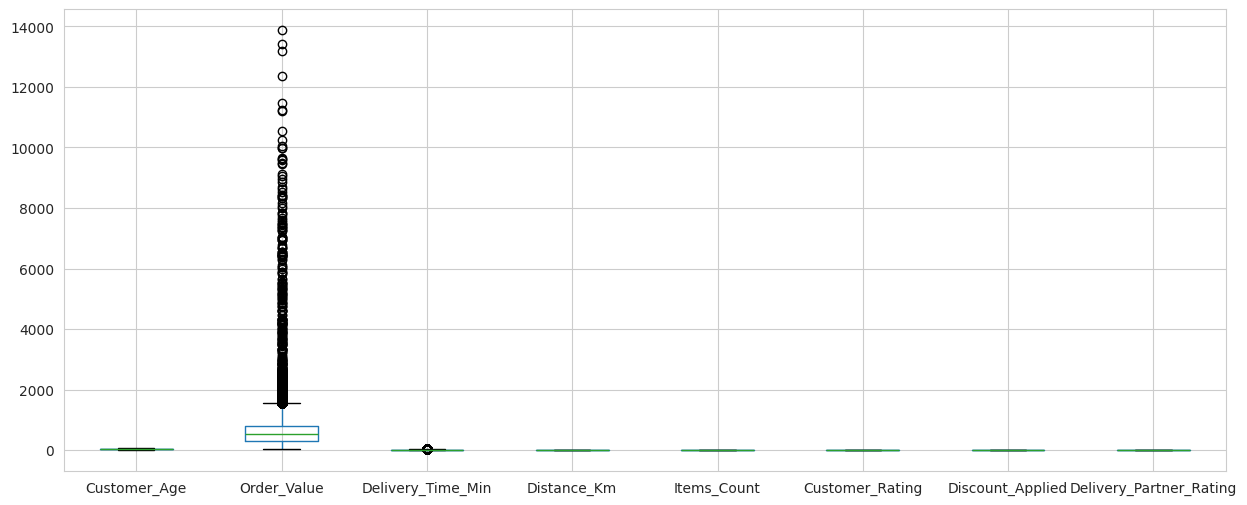

In [122]:
# Box plot

plt.figure(figsize=(15,6))

# Since order id is unique it has high difference in box plot, it is removed since not required
data.drop(columns = ['Order_ID']).boxplot()


In [123]:
# There is high value of Outlier in Order value
# It may or may not be considered : In our case we are not considering this outlier

# Method to remove Outlier :
#     1] Percentile Caping method
data['Order_Value'].clip(upper=2500)


,Order_Value
0,702.33750
1,1007.30000
2,1211.66000
3,1179.05925
4,586.02550
...,...
999995,72.33000
999996,1509.66300
999997,637.32300
999998,1103.12100


In [124]:
    # 2] Filtering
data = data[data['Order_Value'] <= 2500]

<Axes: >

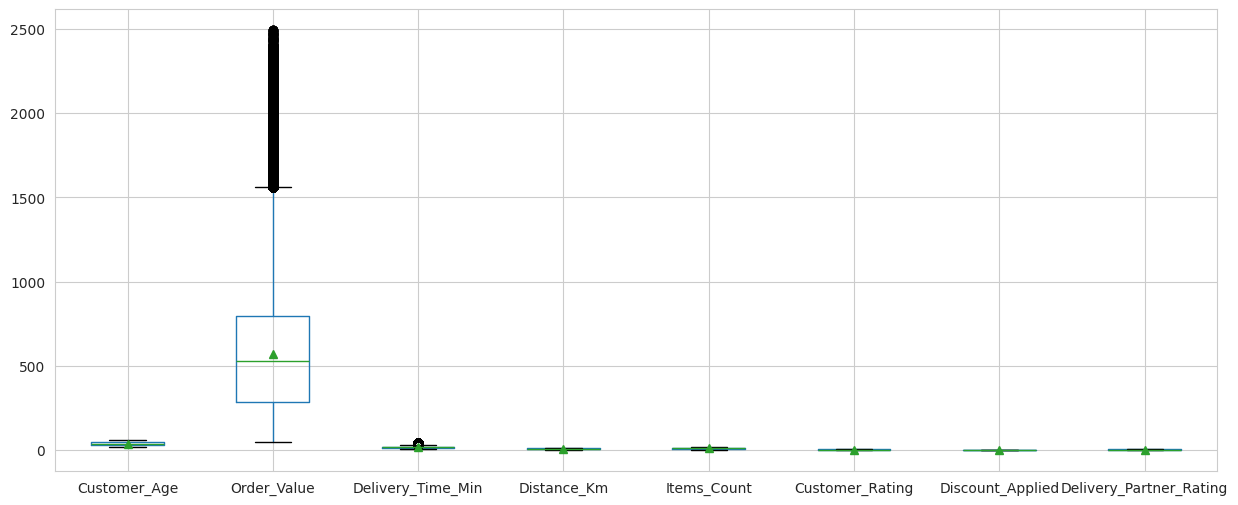

In [125]:
# Now show the boxplot with cap on order value[2500]
plt.figure(figsize=(15,6))

# Since order id is unique it has high difference in box plot, it is removed since not required
data.drop(columns = ['Order_ID']).boxplot(showmeans=True)

In [126]:
data.describe()

,Order_ID,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
count,9.477520e+05,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000
mean,1.500028e+06,38.471165,570.912385,16.502070,7.750046,10.313292,3.042843,0.400786,3.749173
std,2.887273e+05,12.118982,374.174789,6.330106,4.186990,5.630770,1.161112,0.490058,0.684365
min,1.000001e+06,18.000000,50.000000,5.000000,0.500000,1.000000,1.000000,0.000000,2.500000
25%,1.249939e+06,28.000000,287.923000,12.362000,4.130000,5.000000,2.100000,0.000000,3.200000
50%,1.500026e+06,38.000000,531.674100,16.384000,7.750000,10.000000,3.015637,0.000000,3.753051
75%,1.750145e+06,49.000000,796.556650,20.302000,11.380000,15.000000,4.000000,1.000000,4.300000
max,2.000000e+06,59.000000,2492.435250,40.000000,15.000000,19.000000,5.000000,1.000000,5.000000


In [127]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 947752 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 947752 non-null  int64  
 1   Company                  947752 non-null  object 
 2   City                     947752 non-null  object 
 3   Customer_Age             947752 non-null  int64  
 4   Order_Value              947752 non-null  float64
 5   Delivery_Time_Min        947752 non-null  float64
 6   Distance_Km              947752 non-null  float64
 7   Items_Count              947752 non-null  float64
 8   Product_Category         947752 non-null  object 
 9   Payment_Method           947752 non-null  object 
 10  Customer_Rating          947752 non-null  float64
 11  Discount_Applied         947752 non-null  int64  
 12  Delivery_Partner_Rating  947752 non-null  float64
dtypes: float64(6), int64(3), object(4)
memory usage: 101.2+ MB


Change Column Data-type


In [128]:
# Change datatype of order id
data['Order_ID'] = data['Order_ID'].astype(str)

/tmp/ipykernel_4801/1153813792.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [129]:
# Round-off float Values

data['Order_Value'] = np.round(data['Order_Value'])

data['Delivery_Time_Min'] = np.round(data['Delivery_Time_Min'])

data['Distance_Km'] = np.round(data['Distance_Km'], 1) #1 is used to show 1 integer after decimal

data['Delivery_Partner_Rating'] = np.round(data['Delivery_Partner_Rating'])

data['Customer_Rating'] = np.round(data['Customer_Rating'])

/tmp/ipykernel_4801/1057258441.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801/1057258441.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801/1057258441.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801

In [130]:
# Convert float to integer

data['Order_Value'] = data['Order_Value'].astype(int)

data['Delivery_Time_Min'] = data['Delivery_Time_Min'].astype(int)

data['Delivery_Partner_Rating'] = data['Delivery_Partner_Rating'].astype(int)

data['Customer_Rating'] = data['Customer_Rating'].astype(int)

data['Items_Count'] = data['Items_Count'].astype(int)

/tmp/ipykernel_4801/3340371107.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801/3340371107.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801/3340371107.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_4801

In [131]:
data.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5


In [132]:
# check data structure
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 947752 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 947752 non-null  object 
 1   Company                  947752 non-null  object 
 2   City                     947752 non-null  object 
 3   Customer_Age             947752 non-null  int64  
 4   Order_Value              947752 non-null  int64  
 5   Delivery_Time_Min        947752 non-null  int64  
 6   Distance_Km              947752 non-null  float64
 7   Items_Count              947752 non-null  int64  
 8   Product_Category         947752 non-null  object 
 9   Payment_Method           947752 non-null  object 
 10  Customer_Rating          947752 non-null  int64  
 11  Discount_Applied         947752 non-null  int64  
 12  Delivery_Partner_Rating  947752 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 101.2+ MB


Save this Cleaned and modified Dataset

In [133]:
new_path = r"quick_commerce_data_cleaned.csv"

In [134]:
data.to_csv(new_path, index=False)

Load New and Modified Dataset

In [135]:
pd.read_csv(r'quick_commerce_data_cleaned.csv')

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
947747,1999996,Big Basket,Mumbai,48,72,18,3.0,19,Fruits & Vegetables,Wallet,4,0,3
947748,1999997,Swiggy Instamart,Mumbai,33,1510,18,10.5,9,Beverages,Debit Card,4,1,4
947749,1999998,Jio Mart,Noida,29,637,18,2.6,6,Groceries,Cash on Delivery,3,0,5
947750,1999999,Dunzo,Pune,42,1103,13,7.8,12,Snacks,Wallet,4,1,4


Which quick commerce platform has the hihest total revenue?

In [136]:
data.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5


In [137]:
company_revenue = data.groupby('Company')['Order_Value'].sum().sort_values(ascending=False)
company_revenue
#company_revenue is saved as series thus it has index->company and values->total_order_value

,Order_Value
Company,
Swiggy Instamart,76407756
Blinkit,72499575
Zepto,70339672
Big Basket,67884762
Flipkart Minutes,66998289
Amazon Now,65832504
Dunzo,64007579
Jio Mart,57112860


/tmp/ipykernel_4801/1729160442.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




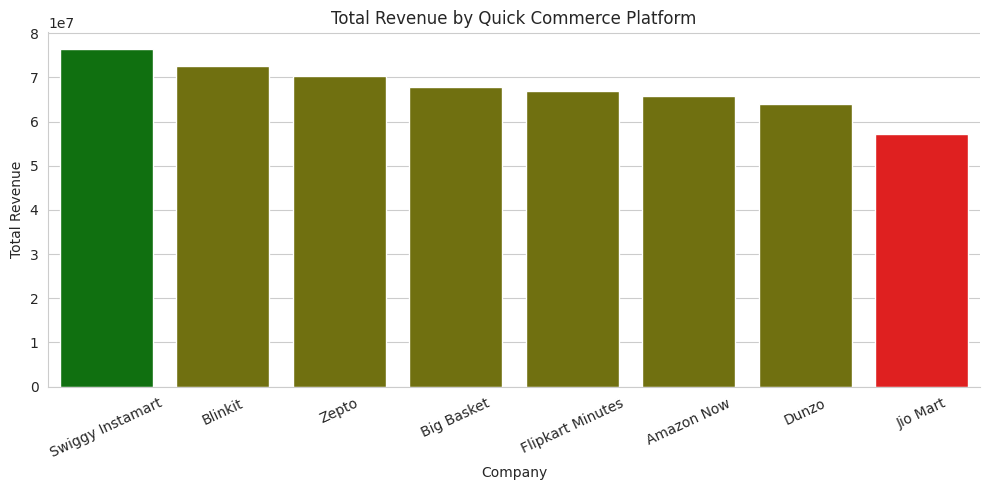

In [138]:
# Bar Plot

# Find min and max revenue
max_rev = company_revenue.max()
min_rev = company_revenue.min()

# Providing color pallette
colors = ['green' if val == max_rev else
         'red' if val == min_rev else
         'olive'
         for val in company_revenue]

# Create a figure
plt.figure(figsize=(10,5))
sns.barplot(company_revenue, palette=colors)
plt.xlabel('Company')
plt.ylabel('Total Revenue')
plt.title('Total Revenue by Quick Commerce Platform')
plt.xticks(rotation=25)


ax = plt.gca() # gca=>Get Current Axis
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.show()

Which Platform has the highest average order revenue(AOV)?


In [139]:
AOV = data.groupby('Company')['Order_Value'].mean().sort_values()
AOV

,Order_Value
Company,
Jio Mart,482.914592
Dunzo,540.317053
Amazon Now,557.510429
Flipkart Minutes,563.176472
Big Basket,575.065542
Zepto,593.258314
Blinkit,609.819198
Swiggy Instamart,644.927250


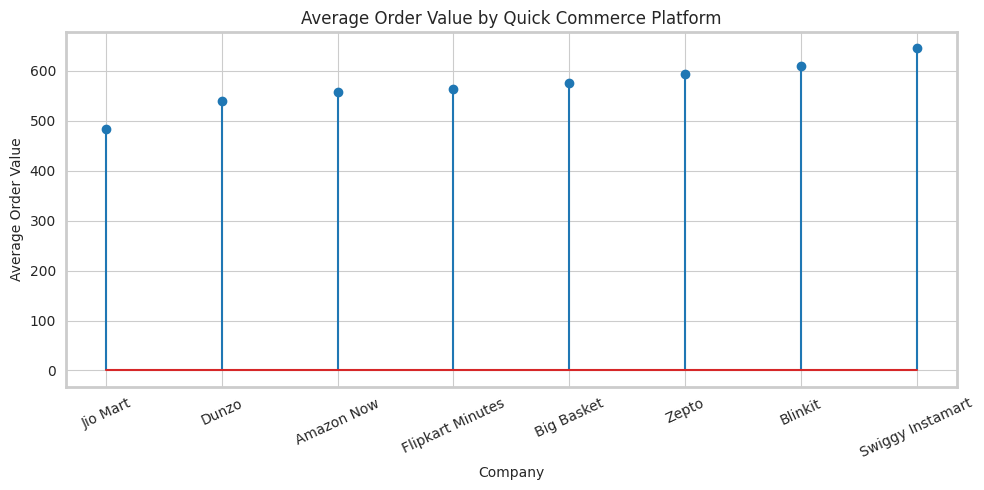

In [140]:
from re import A
# provide visualization
plt.figure(figsize=(10,5))

#Stem chart
plt.stem(AOV.index, AOV.values)
plt.xlabel('Company')
plt.ylabel('Average Order Value')
plt.title('Average Order Value by Quick Commerce Platform')
plt.xticks(rotation=25)

ax = plt.gca()

ax.spines['top'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

plt.tight_layout()
plt.show()

How does customer rating vary across platforms?


In [141]:
avg_cust_rating = data.groupby('Company')['Customer_Rating'].mean().sort_values()
avg_cust_rating

,Customer_Rating
Company,
Dunzo,2.428024
Jio Mart,2.819747
Amazon Now,2.913417
Flipkart Minutes,3.016316
Big Basket,3.097902
Zepto,3.203062
Swiggy Instamart,3.279443
Blinkit,3.580762


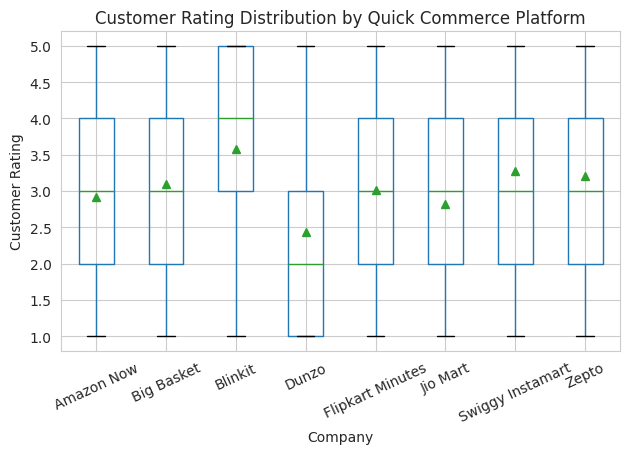

In [142]:
# Visualize
data.boxplot(column='Customer_Rating', by='Company', showmeans=True)

plt.xlabel('Company')
plt.ylabel('Customer Rating')
plt.title('Customer Rating Distribution by Quick Commerce Platform')
plt.xticks(rotation=25)

plt.suptitle('') # Used to remove the default title

plt.tight_layout()
plt.show()

In [143]:
#To check count of each rating per company
grp_rating = data.groupby(['Company', 'Customer_Rating']).size().unstack(fill_value=0)
grp_rating

Customer_Rating,1,2,3,4,5
Company,,,,,
Amazon Now,15977,30351,30866,29697,11192
Big Basket,10143,30339,31020,30908,15637
Blinkit,1060,25553,25561,36708,30005
Dunzo,29818,36280,25377,25818,1170
Flipkart Minutes,12549,30786,31225,30985,13420
Jio Mart,18513,30515,31083,30089,8067
Swiggy Instamart,5000,30278,31039,30931,21227
Zepto,7618,29763,31367,30559,19258


<Figure size 1500x800 with 0 Axes>

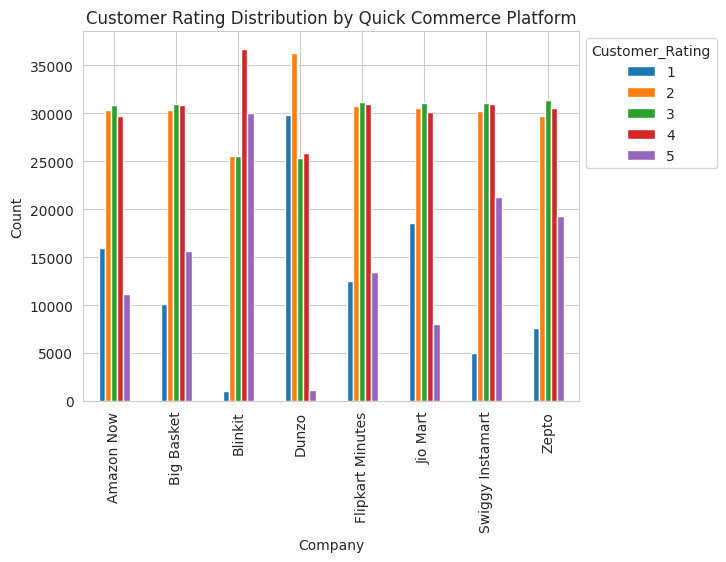

In [144]:

# Visualize
plt.figure(figsize=(15,8))
grp_rating.plot(kind='bar')


plt.xlabel('Company')
plt.ylabel('Count')
plt.title('Customer Rating Distribution by Quick Commerce Platform')
plt.xticks(rotation=90)
plt.legend(title='Customer_Rating', bbox_to_anchor=(1,1), loc='upper left')

plt.show()

Does delivery time affect delivery partner ratings?


In [145]:
data.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5


In [146]:
data['Delivery_Time_Min'].mean()

np.float64(16.506619875241626)

In [147]:
data['Delivery_Partner_Rating'].mean()

np.float64(3.80029480285982)

In [148]:
relation_deliverytime_deliverypartner = data.groupby('Delivery_Time_Min')['Delivery_Partner_Rating'].mean()
relation_deliverytime_deliverypartner

,Delivery_Partner_Rating
Delivery_Time_Min,
5,3.803956
6,3.798555
7,3.805901
8,3.803807
9,3.804469
10,3.801688
11,3.799953
12,3.798843
13,3.795841


In [149]:
data['Delivery_Time_Min'].corr(data['Delivery_Partner_Rating'])
# There is not much difference

np.float64(-0.002777340802669754)

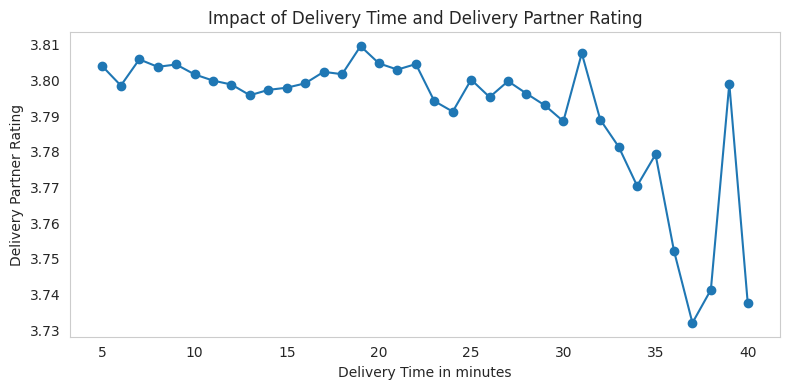

In [150]:
# Visualization

plt.figure(figsize=(8,4))
relation_deliverytime_deliverypartner.plot(marker='o')
plt.xlabel('Delivery Time in minutes')
plt.ylabel('Delivery Partner Rating')
plt.title('Impact of Delivery Time and Delivery Partner Rating')
plt.grid()

plt.tight_layout()
plt.show()

In [151]:
data['Delivery_Time_Bucket'] = pd.cut(data['Delivery_Time_Min'],
                                      bins=(0, 10, 20, 30, 40, 50),
                                      labels=('Very fast delivery', 'Fast delivery', 'Normal delivery', 'Slow delivery', 'Very slow delivery'))

/tmp/ipykernel_4801/179048567.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [152]:
data.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating,Delivery_Time_Bucket
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3,Fast delivery
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3,Fast delivery
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4,Fast delivery
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5,Very fast delivery
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5,Fast delivery


In [153]:
# Now group by delivery bucket
bucket_avg = data.groupby('Delivery_Time_Bucket')['Delivery_Partner_Rating'].mean()
bucket_avg

/tmp/ipykernel_4801/31617613.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,Delivery_Partner_Rating
Delivery_Time_Bucket,
Very fast delivery,3.803231
Fast delivery,3.800835
Normal delivery,3.798345
Slow delivery,3.783646
Very slow delivery,NaN


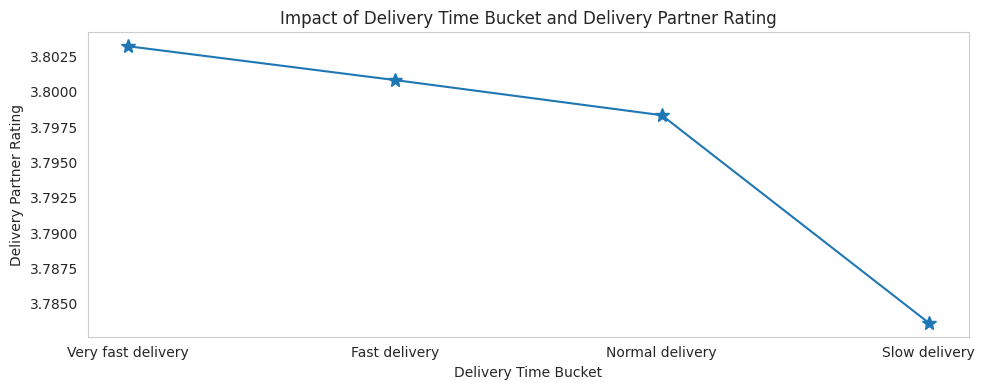

In [154]:
# Visualize
plt.figure(figsize=(10,4))

bucket_avg.plot(marker='*', markersize=10)

plt.xlabel('Delivery Time Bucket')
plt.ylabel('Delivery Partner Rating')
plt.title('Impact of Delivery Time Bucket and Delivery Partner Rating')
plt.grid()

plt.tight_layout()

plt.show()

What is the most popular Product Category on Swiggy Instamart, for the people of age between 30-40, in Mumbai?

In [155]:
df_prod_cat = data[
              (data['Company']=='Swiggy Instamart')
              & ((data['Customer_Age']>=30)
              & (data['Customer_Age'] < 40)
              & (data['City']=='Mumbai'))]
df_prod_cat

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating,Delivery_Time_Bucket
536,1000537,Swiggy Instamart,Mumbai,38,1157,14,5.7,18,Beverages,Cash on Delivery,4,1,4,Fast delivery
909,1000910,Swiggy Instamart,Mumbai,32,926,20,14.2,3,Dairy,UPI,2,0,5,Fast delivery
1203,1001204,Swiggy Instamart,Mumbai,37,234,19,7.6,6,Dairy,Debit Card,5,0,4,Fast delivery
2918,1002919,Swiggy Instamart,Mumbai,31,423,15,4.0,10,Dairy,Cash on Delivery,2,0,3,Fast delivery
4251,1004252,Swiggy Instamart,Mumbai,36,50,15,2.2,12,Dairy,Credit Card,3,0,3,Fast delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997610,1997611,Swiggy Instamart,Mumbai,37,448,19,14.0,17,Fruits & Vegetables,Cash on Delivery,5,0,5,Fast delivery
999242,1999243,Swiggy Instamart,Mumbai,32,747,13,2.4,12,Household,UPI,5,1,5,Fast delivery
999258,1999259,Swiggy Instamart,Mumbai,35,50,18,7.6,4,Personal Care,Debit Card,5,0,5,Fast delivery
999680,1999681,Swiggy Instamart,Mumbai,39,375,19,8.7,6,Household,Wallet,2,0,4,Fast delivery


In [156]:
# most popular product category
df_prod_cat['Product_Category'].value_counts()

,count
Product_Category,
Dairy,368
Fruits & Vegetables,343
Groceries,341
Household,340
Snacks,329
Personal Care,305
Beverages,299


Which cities should these company expand into based on performance?


In [157]:
data

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating,Delivery_Time_Bucket
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3,Fast delivery
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3,Fast delivery
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4,Fast delivery
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5,Very fast delivery
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5,Fast delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,1999996,Big Basket,Mumbai,48,72,18,3.0,19,Fruits & Vegetables,Wallet,4,0,3,Fast delivery
999996,1999997,Swiggy Instamart,Mumbai,33,1510,18,10.5,9,Beverages,Debit Card,4,1,4,Fast delivery
999997,1999998,Jio Mart,Noida,29,637,18,2.6,6,Groceries,Cash on Delivery,3,0,5,Fast delivery
999998,1999999,Dunzo,Pune,42,1103,13,7.8,12,Snacks,Wallet,4,1,4,Fast delivery


In [158]:
from matplotlib.patches import CirclePolygon
# Group data and apply appropriate functions
city_performance = data.groupby(['Company', 'City']).agg(
                                      Total_Orders = ('Order_ID', 'count'),
                                      Avg_Rating = ('Customer_Rating', 'mean'),
                                      Avg_Delivery_Time = ('Delivery_Time_Min', 'mean'),
                                      Total_Revenue = ('Order_Value', 'sum')
                                      ).reset_index()
city_performance


,Company,City,Total_Orders,Avg_Rating,Avg_Delivery_Time,Total_Revenue
0,Amazon Now,Amritsar,9929,2.896666,18.167388,5469439
1,Amazon Now,Bengluru,9905,3.387683,19.183342,5629936
2,Amazon Now,Chennai,9847,2.904032,18.138722,5363559
3,Amazon Now,Delhi,9918,2.989716,8.294616,5891026
4,Amazon Now,Gurgaon,9797,2.921711,18.166173,6680388
...,...,...,...,...,...,...
91,Zepto,Jaipur,9678,3.112213,13.145278,4621428
92,Zepto,Kolkata,9825,3.173028,8.302901,5776955
93,Zepto,Mumbai,9861,3.412230,10.152013,6046485
94,Zepto,Noida,10070,3.206653,8.297617,7070769


In [159]:
# Filtering best cities based on provided conditions
best_cities = city_performance[
                              (city_performance['Avg_Rating']>=3.5) &
                              (city_performance['Avg_Delivery_Time']<=15) &
                              (city_performance['Total_Orders']>city_performance['Total_Orders'].median())
]
best_cities

,Company,City,Total_Orders,Avg_Rating,Avg_Delivery_Time,Total_Revenue
24,Blinkit,Amritsar,9932,3.589106,14.199154,6006361
26,Blinkit,Chennai,9876,3.580903,14.135581,5921870
28,Blinkit,Gurgaon,10078,3.579381,14.199345,7374774
32,Blinkit,Kolkata,10004,3.566873,14.142743,6003384
35,Blinkit,Pune,9908,3.583266,14.164110,5930415
85,Zepto,Bengluru,9971,3.598636,9.198977,6041668


In [160]:
best_cities[['Company', 'City']]

,Company,City
24,Blinkit,Amritsar
26,Blinkit,Chennai
28,Blinkit,Gurgaon
32,Blinkit,Kolkata
35,Blinkit,Pune
85,Zepto,Bengluru


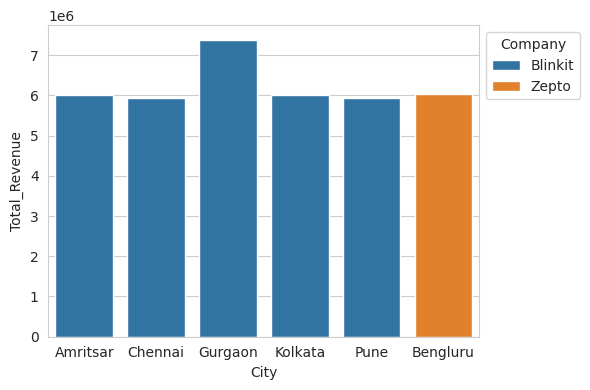

In [161]:
from pandas.plotting import parallel_coordinates
# Ploting
plt.figure(figsize=(6,4))
sns.barplot(data=best_cities, x='City', y='Total_Revenue', hue='Company')
plt.legend(title='Company', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

Are discounts increasing order volume or just reducing revenue?


In [162]:
data.head()


,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating,Delivery_Time_Bucket
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3,Fast delivery
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,12.7,10,Snacks,Cash on Delivery,2,0,3,Fast delivery
2,1000003,Flipkart Minutes,Mumbai,18,1212,17,4.8,19,Personal Care,Cash on Delivery,3,0,4,Fast delivery
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.4,2,Dairy,Credit Card,5,1,5,Very fast delivery
4,1000005,Dunzo,Mumbai,44,586,12,2.4,13,Household,Wallet,4,0,5,Fast delivery


In [163]:
x = data['Discount_Applied'].unique()
x

array([1, 0])

In [164]:
# Number of orders with and without discounts
data['Discount_Applied'].value_counts()

,count
Discount_Applied,
0,567906
1,379846


In [165]:
# Group data- Calculate average order value
dis_order_val = data.groupby('Discount_Applied')['Order_Value'].mean()
dis_order_val

,Order_Value
Discount_Applied,
0,476.417152
1,712.190830


In [166]:
# Group data- Sum of items count
dis_item_count = data.groupby('Discount_Applied')['Items_Count'].sum()
dis_item_count

,Items_Count
Discount_Applied,
0,5854258
1,3920185


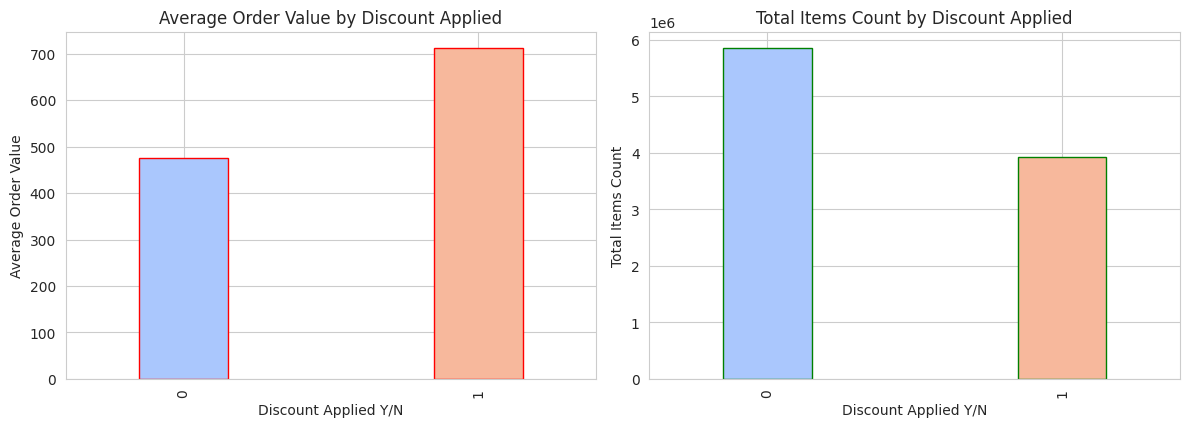

In [167]:
# Plotting
plt.figure(figsize=(12,8))
colors = sns.color_palette('coolwarm', len(x))

plt.subplot(2,2,1)

dis_order_val.plot(kind='bar', width=0.3, edgecolor='red', color=colors)
plt.title('Average Order Value by Discount Applied')
plt.ylabel('Average Order Value')
plt.xlabel('Discount Applied Y/N')

plt.subplot(2,2,2)

dis_item_count.plot(kind='bar', width=0.3, edgecolor='green', color=colors)
plt.title('Total Items Count by Discount Applied')
plt.ylabel('Total Items Count')
plt.xlabel('Discount Applied Y/N')

plt.tight_layout()

plt.show()

Which company has the Best Operational Efficiency(Delivery Time vs Order Volume)

In [168]:
# Group data and apply aggregation
company_efficiency = data.groupby('Company').agg(
                                                Total_Orders = ('Order_ID', 'count'),
                                                Avg_Delivery_Time = ('Delivery_Time_Min', 'mean')
                                                ).reset_index()
company_efficiency

,Company,Total_Orders,Avg_Delivery_Time
0,Amazon Now,118083,18.984155
1,Big Basket,118047,18.027345
2,Blinkit,118887,15.121771
3,Dunzo,118463,14.177060
4,Flipkart Minutes,118965,17.045080
5,Jio Mart,118267,23.013224
6,Swiggy Instamart,118475,16.072690
7,Zepto,118565,9.644313


In [169]:
# Normalize values for fair comparison
from sklearn.preprocessing import MinMaxScaler

# Scaling both columns to the same range (0 to 1) so that they can be fairly compared and combined
scaler = MinMaxScaler()  # Create a scaling object

company_efficiency[['Total_Orders_Scaled', 'Avg_Delivery_Time_Scaled']] = scaler.fit_transform(company_efficiency[['Total_Orders','Avg_Delivery_Time']])


In [170]:
company_efficiency

,Company,Total_Orders,Avg_Delivery_Time,Total_Orders_Scaled,Avg_Delivery_Time_Scaled
0,Amazon Now,118083,18.984155,0.039216,0.698624
1,Big Basket,118047,18.027345,0.000000,0.627054
2,Blinkit,118887,15.121771,0.915033,0.409716
3,Dunzo,118463,14.177060,0.453159,0.339051
4,Flipkart Minutes,118965,17.045080,1.000000,0.553580
5,Jio Mart,118267,23.013224,0.239651,1.000000
6,Swiggy Instamart,118475,16.072690,0.466231,0.480845
7,Zepto,118565,9.644313,0.564270,0.000000


In [171]:
# Efficiency Score

company_efficiency['Efficiency_Score'] = company_efficiency['Total_Orders_Scaled'] - company_efficiency['Avg_Delivery_Time_Scaled']


In [172]:
company_efficiency

,Company,Total_Orders,Avg_Delivery_Time,Total_Orders_Scaled,Avg_Delivery_Time_Scaled,Efficiency_Score
0,Amazon Now,118083,18.984155,0.039216,0.698624,-0.659408
1,Big Basket,118047,18.027345,0.000000,0.627054,-0.627054
2,Blinkit,118887,15.121771,0.915033,0.409716,0.505317
3,Dunzo,118463,14.177060,0.453159,0.339051,0.114108
4,Flipkart Minutes,118965,17.045080,1.000000,0.553580,0.446420
5,Jio Mart,118267,23.013224,0.239651,1.000000,-0.760349
6,Swiggy Instamart,118475,16.072690,0.466231,0.480845,-0.014614
7,Zepto,118565,9.644313,0.564270,0.000000,0.564270


In [173]:
eff = company_efficiency.sort_values(by='Efficiency_Score', ascending=False)

In [174]:
eff

,Company,Total_Orders,Avg_Delivery_Time,Total_Orders_Scaled,Avg_Delivery_Time_Scaled,Efficiency_Score
7,Zepto,118565,9.644313,0.564270,0.000000,0.564270
2,Blinkit,118887,15.121771,0.915033,0.409716,0.505317
4,Flipkart Minutes,118965,17.045080,1.000000,0.553580,0.446420
3,Dunzo,118463,14.177060,0.453159,0.339051,0.114108
6,Swiggy Instamart,118475,16.072690,0.466231,0.480845,-0.014614
1,Big Basket,118047,18.027345,0.000000,0.627054,-0.627054
0,Amazon Now,118083,18.984155,0.039216,0.698624,-0.659408
5,Jio Mart,118267,23.013224,0.239651,1.000000,-0.760349


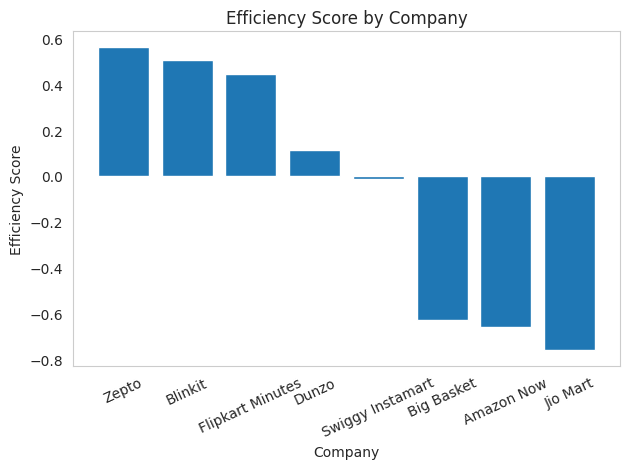

In [175]:
plt.bar(eff['Company'], eff['Efficiency_Score'])

plt.xlabel('Company')
plt.ylabel('Efficiency Score')
plt.title('Efficiency Score by Company')
plt.xticks(rotation=25)

plt.grid()

plt.tight_layout()
plt.show()

In [176]:
from matplotlib.axis import XAxis
# Use Plotly library - Scatter Bubble Plot

# create positive bubble size
min_eff = eff['Efficiency_Score'].min()
eff['Bubble_Size'] = eff['Efficiency_Score'] - min_eff + 0.1

#Plot
fig = px.scatter(eff, x='Total_Orders', y='Avg_Delivery_Time', size='Bubble_Size', color='Company',
                 text='Company', title='Operational Efficiency of Quick Commerce Platforms',
                 hover_data={'Total_Orders':True, "Avg_Delivery_Time": ':.2f', "Efficiency_Score":':.3f'},
                 size_max=40)

# Make labels cleaner
fig.update_traces(textposition='middle center')

# Improve chart
fig.update_layout(
                  xaxis_title='Total Orders (Higher is Beter)',
                  yaxis_title='Average Delivery Time in minutes (Lower is Better)',
                  title_x=0.5,
                  template='plotly_dark',
                  height=600
                )

# Reversing the Y-axis so best performance appears higher
fig.update_yaxes(autorange='reversed')

fig.show()

MINI Dashboard

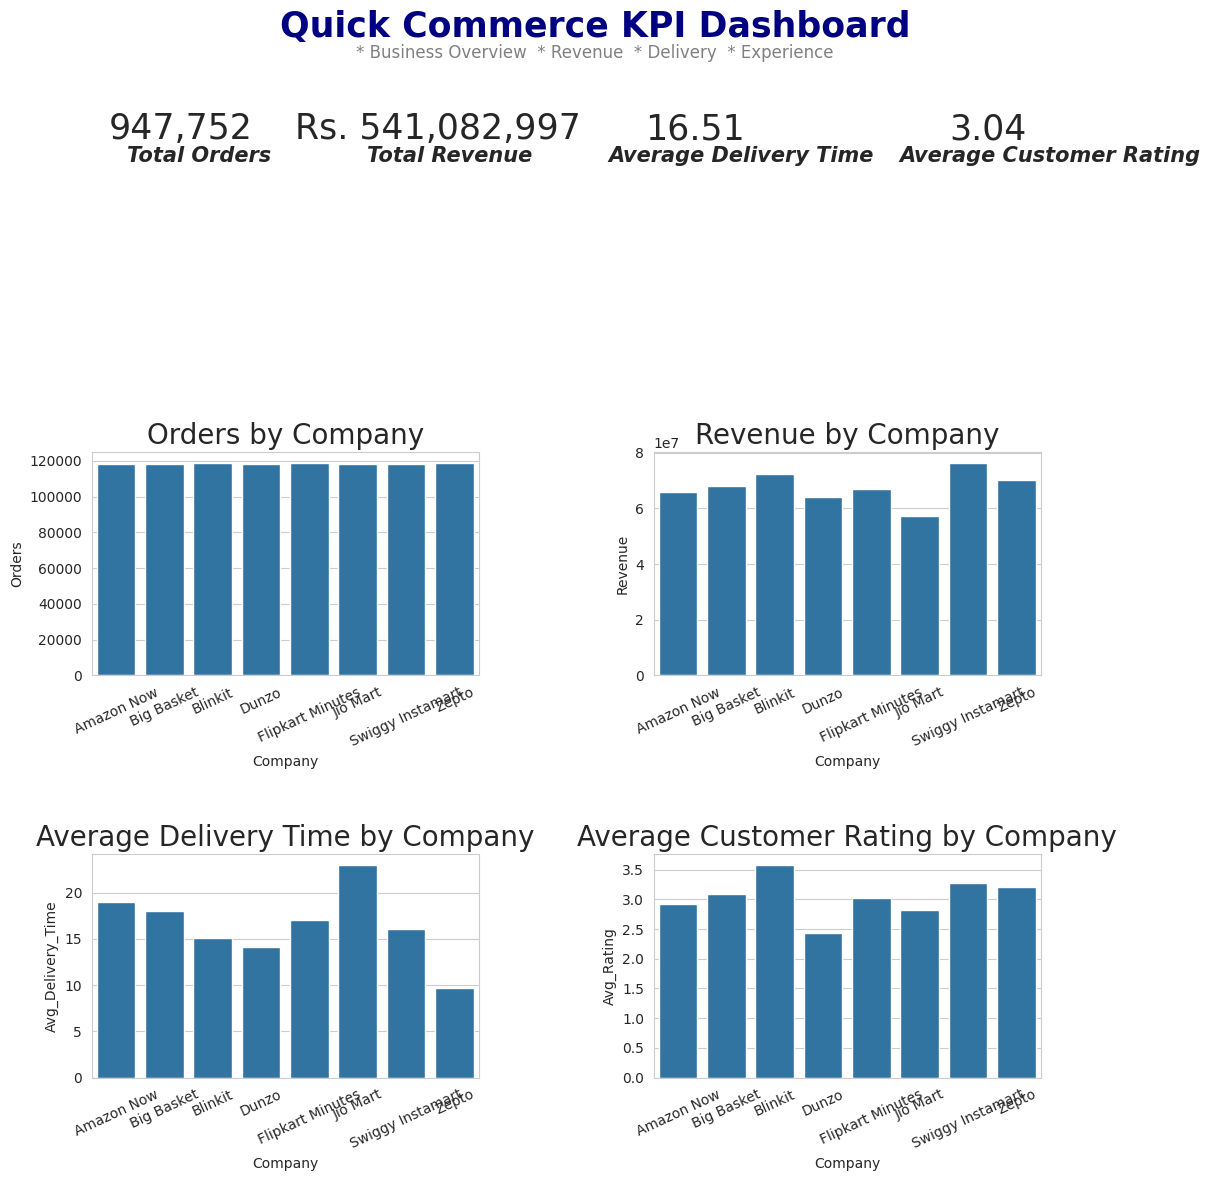

In [177]:
# Create dashboard layout
#---------------------------------
fig = plt.figure(figsize=(12,12))
sns.set_style('whitegrid')

#-------------------------------------
# KPI[K Performance Indicators] Calculation
#-------------------------------------
total_orders = data['Order_ID'].count()
total_revenue = data['Order_Value'].sum()
avg_delivery_time = data['Delivery_Time_Min'].mean()
avg_rating = data['Customer_Rating'].mean()

#----------------------
#KPI CARDS
#----------------------
plt.subplot2grid((3,4), (0,0))
plt.axis('off')
plt.text(0.5, 0.6, f"{total_orders:,}", fontsize=25, ha='center')
plt.text(0.2, 0.5, 'Total Orders', fontsize=15, fontstyle='italic', fontweight='bold')

plt.subplot2grid((3,4), (0,1))
plt.axis('off')
plt.text(0.5, 0.6, f"Rs. {total_revenue:,}", fontsize=25, ha='center')
plt.text(0.1, 0.5, 'Total Revenue', fontsize=15, fontstyle='italic', fontweight='bold')

plt.subplot2grid((3,4), (0,2))
plt.axis('off')
plt.text(0.5, 0.6, f"{avg_delivery_time:.2f}", fontsize=25, ha='center')
plt.text(0.01, 0.5, 'Average Delivery Time', fontsize=15, fontstyle='italic', fontweight='bold')

plt.subplot2grid((3,4), (0,3))
plt.axis('off')
plt.text(0.7, 0.6, f"{avg_rating:.2f}", fontsize=25, ha='center')
plt.text(0.2, 0.5, 'Average Customer Rating', fontsize=15, fontstyle='italic', fontweight='bold')

#----------------------
# Company Level Metrics
#----------------------
company_metrics = data.groupby('Company').agg(Orders = ('Order_ID', 'count'),
                            Revenue = ('Order_Value', 'sum'),
                            Avg_Delivery_Time = ('Delivery_Time_Min', 'mean'),
                            Avg_Rating = ('Customer_Rating', 'mean')).reset_index()

#------------------------
# Charts Section
#------------------------

# Orders by Company
plt.subplot2grid((3,2), (1,0))
sns.barplot(data=company_metrics, x='Company', y='Orders')
plt.title('Orders by Company', fontsize=20)
plt.xticks(rotation=25)

# Revenue by Company
plt.subplot2grid((3,2), (1,1))
sns.barplot(data=company_metrics, x='Company', y='Revenue')
plt.title('Revenue by Company', fontsize=20)
plt.xticks(rotation=25)

# Average delivery time by company
plt.subplot2grid((3,2), (2,0))
sns.barplot(data=company_metrics, x='Company', y='Avg_Delivery_Time')
plt.title('Average Delivery Time by Company', fontsize=20)
plt.xticks(rotation=25)

# Average customer rating by company
plt.subplot2grid((3,2), (2,1))
sns.barplot(data=company_metrics, x='Company', y='Avg_Rating')
plt.title('Average Customer Rating by Company', fontsize=20)
plt.xticks(rotation=25)

#-------------------
# Dashboard Title
#-------------------
plt.rcParams['font.family']="Times New Roman"
plt.suptitle('Quick Commerce KPI Dashboard', fontsize=25, fontweight='bold', color='navy')
plt.figtext(0.5, 0.94, '* Business Overview  * Revenue  * Delivery  * Experience', ha='center', fontsize=12, color='gray')

plt.tight_layout()
plt.subplots_adjust(hspace=0.8)
plt.show()

## Key Findings

- **Revenue varies significantly across platforms** — the highest-revenue platform is clearly separated from the lowest in total order value, with colour-coded bar charts making the winner instantly visible (green = highest, red = lowest).

- **Average Order Value (AOV) differences are smaller than total revenue gaps** — suggesting the revenue leader wins on order volume, not necessarily on larger basket sizes — a key operational insight for pricing strategy.

- **Customer ratings are consistent across platforms** (clustered around 3–4 stars) — no single platform has a dramatically superior customer experience score, indicating the q-commerce industry as a whole has a ratings ceiling to break through.

- **Delivery time has near-zero correlation with delivery partner ratings** — the correlation score confirms that faster delivery does NOT significantly improve partner ratings; other factors like app usability, payment reliability, and tip structure matter more.

- **"Very Fast Delivery" (under 10 min) shows only marginally higher partner ratings** — the delivery bucket analysis confirms that the relationship between speed and partner satisfaction is flat, challenging the assumption that faster = happier partners.

- **Swiggy Instamart customers in Mumbai aged 30–40 prefer Personal Care products** the most — a hyper-specific business intelligence query demonstrating the power of multi-condition filtering for real-world marketing decisions.

- **Best cities for expansion are those with Avg Rating ≥ 3.5, Avg Delivery Time ≤ 15 mins, and above-median order volume** — the multi-condition filter identifies cities where the platform already performs well and can scale efficiently.

- **Discounts increase item volume but reduce average order value** — orders with discounts applied have higher Items_Count totals but lower per-order revenue, confirming that discounts drive volume at the cost of margin — a classic trade-off in q-commerce.

- **Operational Efficiency Score (MinMaxScaler method)** ranks platforms by combining scaled order volume and scaled delivery time — the top scorer handles the most orders in the least time, making it the operationally strongest platform in the dataset.

- **Advanced techniques used:** Group-wise mean imputation using `transform(lambda)`, outlier removal via percentile capping and filtering, MinMaxScaler normalisation from Scikit-learn, Plotly bubble scatter charts, and a multi-panel Matplotlib KPI dashboard — demonstrating a significant step up in complexity from standard EDA.